<div style="border-left:4px solid #3D6FB0;padding:6px 0 8px 16px;"><div style="opacity:.72;font-size:12px;letter-spacing:1.4px;">Datos Masivos II · PRÁCTICA 4</div><div style="color:#3D6FB0;font-size:27px;font-weight:700;margin-top:4px;">BindingDB: sistema de recomendación híbrido</div><div style="opacity:.72;font-size:14px;margin-top:6px;margin-bottom:10px;">Equipo Tres: Castrillo Cruz Karen Arlet, Ramos González Nadia, Zamora Antiga Ángel Javier.</div><img src="https://mmss.iimas.unam.mx/dmmss/wp-content/uploads/2026/02/cropped-LogoUNAM_IIMAS_Negro50-scaled-2.png" width="200"/></div>

## Propósito

Desde la matriz generada en `BindingDB_Limpieza.ipynb` se **entrena, evalúa y compara** un sistema de recomendación híbrido.

### Qué se entrena

| Modelo | Predice con | Deja de funcionar cuando |
|---|---|---|
| Líneas base | el promedio, la popularidad, el azar | nunca, y por eso son el piso a vencer |
| **Colaborativo** | otras proteínas parecidas que midieron **este mismo** ligando | el ligando es **nuevo** |
| **Contenido** | ligandos **parecidos a este** que **esta misma** proteína ya midió | la proteína es **nueva** |
| **Híbrido** | los dos anteriores, con peso `α` y conmutación | — |

Los dos modelos centrales fallan en situaciones **complementarias**. Esa es la justificación del híbrido en este problema: no es promediar por gusto, es que cada componente cubre exactamente el hueco del otro.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">1. Qué pregunta estamos modelando</span></div>

### Primero, el vocabulario

La palabra *target* significa tres cosas distintas según quién la use, y confundirlas vuelve ilegible el problema. En este notebook se evita: se dice **proteína** y **ligando**, y la palabra *target* aparece solo como nombre literal de una columna.

| Término | En farmacología | En este notebook |
|---|---|---|
| *target* | la **proteína**, el blanco al que se apunta | la columna `target_id`; cumple el rol de **usuario** |
| *target variable* (ML) | — | la **variable respuesta**: `pIC50` |
| *ligando* | la molécula pequeña que se pega a la proteína | el rol de **ítem** |

Sobre los conceptos sencillos que estamos trabajando:

1. Las proteínas son máquinas moleculares que actúan en los procesos del cuerpo.
2. Un **ligando** es una molécula pequeña que se adhiere a una proteína y le altera el comportamiento. Los fármacos son ligandos.
3. **IC50** es cuánta concentración de ligando hace falta para lograr el efecto. Menos concentración = se adhiere más fuerte = mejor.

### La pregunta, enunciada formalmente

Sean

- $U$ = las **3,444 proteínas** humanas de una sola cadena con al menos un IC50 válido → los *usuarios*
- $I$ = los **832,751 ligandos** → los *ítems*
- $O \subset U \times I$ = los **1,250,494 pares observados**, el $0.0436\%$ de las celdas posibles

Cada par observado $(u,i) \in O$ trae dos etiquetas:

- $r(u,i) \in [2, 12]$ — el `pIC50`, continuo, en escala de energía de unión. **Ausente en el 20.7%** de los pares.
- $a(u,i) \in \{0,1\}$ — `activo`, si $r \ge 6$ (1 µM). **Nunca ausente.**

> **La tarea.** Dada una proteína $u$ y un conjunto de ligandos candidatos $C \subseteq I$, producir un orden de $C$ por potencia esperada y devolver los $k$ mejores.

### Qué afirma exactamente esta tarea, y qué no

Todo depende de **qué es $C$**, y es la decisión que se suele dejar implícita:

- Si $C$ fueran los 832,751 ligandos, esto sería cribado virtual de verdad. Pero **no existe verdad de terreno para el 99.96% de esas celdas**, así que se podrían producir recomendaciones y no se podría saber si son buenas.
- Si $C$ son los ligandos que **sí se midieron** contra $u$ y quedaron en el conjunto de prueba, entonces sí es evaluable, y es lo que se hace aquí.

La afirmación honesta es, por tanto: ***dado un conjunto de compuestos que alguien ya consideró que valía la pena probar contra esta proteína, ¿sabemos ordenarlos por potencia?*** Es más débil que "descubrimos ligandos nuevos", porque el conjunto candidato ya viene filtrado por el criterio de un químico. Pero es la verdadera.

**Corolario que condiciona todo el diseño: lo no observado no es negativo.** En recomendación clásica, que alguien no haya visto una película es evidencia débil de desinterés. Aquí, que un par no esté medido significa casi siempre **que nadie lo probó**, y nadie lo probó porque el espacio es inmenso, no porque se supiera que no se une. Tratar la ausencia como negativo enseñaría al modelo *qué se publica*, no *qué se une*. Por eso **nunca se generan negativos del no-observado**: se entrena y se evalúa solo sobre pares medidos.

### Lo que las decisiones de limpieza ya fijaron

| Decisión (de `BindingDB_Limpieza.ipynb`) | Consecuencia para el modelo |
|---|---|
| `MEDICION = "IC50"` | la variable respuesta mide **adherencia**, no activación funcional. `activo = 1` significa *"se adhiere por debajo de 1 µM"*, **no** *"activa la proteína"*. Lo que mide activación es EC50 y quedó fuera. |
| `UMBRAL = 6.0` | el 61.85% de los pares son activos, **por construcción del umbral**. Por tanto un recomendador **aleatorio acierta ~0.62** de precisión. Esa, y no 0.5, es la línea base. |
| `ESPECIE = "HUMAN"` | se pierde la posibilidad de transferir desde ortólogos de ratón o rata, cuyos bolsillos suelen ser casi idénticos. |
| `SOLO_1_CADENA` | garantiza que "la secuencia de la proteína" esté bien definida, a cambio de excluir complejos de varias cadenas. |
| censura resuelta | el `pIC50` exacto está **enriquecido en compuestos potentes** (se reporta el número cuando funciona y `>10000` cuando no). Entrenar solo con `pIC50` hereda ese sesgo; por eso la evaluación principal usa `activo`, que no lo tiene. |
| `discordante` (19.8% de los repetidos) | es ruido experimental entre laboratorios: **el piso de error**. No tiene sentido perseguir un RMSE por debajo de ~0.5. |

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">2. Entorno y parámetros</span></div>

In [3]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator, Descriptors
from sklearn.metrics import roc_auc_score

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 48)

# ----------------------------- RUTAS -----------------------------
PROC    = Path("data/processed")
IN_INT  = PROC / "rec_interacciones.parquet"     # salida de BindingDB_Limpieza.ipynb
IN_LIG  = PROC / "rec_ligandos.parquet"
IN_TGT  = PROC / "rec_targets.parquet"
OUT_RES = PROC / "rec_resultados.json"
FIG_DIR = Path("figs/recomendador"); FIG_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------- PARÁMETROS ----------------------------
# Lo único que hay que tocar para rehacer el experimento con otro criterio.

# OJO: muestrear proteínas NO es solo "correr más rápido". Al quitar proteínas se quitan
# las co-ocurrencias que sostienen al filtrado colaborativo: cada ligando se queda con un
# único par y todo el test cae en arranque en frío. Para resultados válidos, None.
MUESTRA_PROT  = None     # nº de proteínas; None = las 3,444 (la corrida válida, ~10 min)
MAX_TEST_POR_PROT = 300  # tope de ligandos candidatos por proteína al evaluar; None = todos
UMBRAL        = 6.0      # pIC50 >= UMBRAL => activo. Debe coincidir con la limpieza.
EXCL_CONFLICTO   = True  # quitar los pares con cotas contradictorias
EXCL_DISCORDANTE = False  # quitar los pares con rango > 1 log (ruido experimental)

# Representación del ligando (contenido de ítem)
FP_RADIO  = 2            # Morgan radio 2 == ECFP4
FP_BITS   = 1024         # longitud de la huella

# Representación de la proteína (contenido de usuario)
K_MER     = 2            # k-meros de la secuencia. 2 -> 400 dims, 3 -> 8,000

# Partición
PARTICION = "temporal"   # "temporal" | "ligando" | "aleatoria"
TEST_FRAC = 0.20
ANIO_NULO_A_TRAIN = True

# Vecindarios
K_VEC_PROT   = 30        # vecinos por proteína (colaborativo)
MIN_SOLAPE   = 5         # ligandos en común mínimos para confiar en la similitud
K_VEC_LIG    = 25        # vecinos por ligando (contenido)
MIN_TANIMOTO = 0.15      # por debajo de esto, dos moléculas no se parecen
N_PROT_VEC   = 10        # proteínas vecinas que aportan sus mediciones al híbrido
CAP_VECINO   = 300       # tope de ligandos que se toman de cada proteína vecina
BETA         = 0.5       # mezcla de similitud entre proteínas: 1 = solo co-ocurrencia,
                         # 0 = solo secuencia. Define QUÉ es un vecino de la proteína.

# Evaluación
TOP_K        = 10        # k de precision@k / NDCG@k
MIN_TEST_LIG = 10        # proteínas con menos ligandos en test no se evalúan
ALPHAS       = np.round(np.linspace(0, 1, 11), 2)
SEMILLA      = 0

rng = np.random.default_rng(SEMILLA)

# ----------------------------- ESTILO -----------------------------
AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
CAT = [AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO]
GRIS = "#8a8984"
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "azul", ["#f4f8fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "legend.frameon": False,
    "axes.prop_cycle": cycler(color=CAT),
})

def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight")
    plt.show()

def pct(a, b):
    return 100 * a / b if b else float("nan")

H = {}   # hallazgos para el resumen final

print(f"Partición: {PARTICION} | huella: ECFP{2*FP_RADIO} de {FP_BITS} bits | k-meros: k={K_MER}")
print(f"Proteínas: {'todas' if MUESTRA_PROT is None else MUESTRA_PROT} | umbral activo: pIC50 >= {UMBRAL}")

Partición: temporal | huella: ECFP4 de 1024 bits | k-meros: k=2
Proteínas: todas | umbral activo: pIC50 >= 6.0


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">3. Carga de la matriz</span></div>

In [4]:
t0 = time.time()
I = pd.read_parquet(IN_INT)
L = pd.read_parquet(IN_LIG)
T = pd.read_parquet(IN_TGT)
print(f"Pares: {len(I):,} | ligandos: {len(L):,} | proteínas: {len(T):,}  ({time.time()-t0:.1f}s)")

n0 = len(I)
if EXCL_CONFLICTO:
    I = I[~I["conflicto_cotas"]]
    print(f"- {n0-len(I):,} pares con cotas contradictorias")
if EXCL_DISCORDANTE:
    n1 = len(I); I = I[~I["discordante"]]
    print(f"- {n1-len(I):,} pares discordantes (rango > 1 log)")

# Muestra de proteínas: se eligen al azar pero se conservan TODOS sus pares,
# para no alterar la densidad del perfil de cada proteína.
if MUESTRA_PROT is not None and MUESTRA_PROT < I["target_id"].nunique():
    elegidas = pd.Series(I["target_id"].unique()).sample(MUESTRA_PROT, random_state=SEMILLA)
    I = I[I["target_id"].isin(set(elegidas))]

L = L[L["lig_id"].isin(set(I["lig_id"]))].reset_index(drop=True)
T = T[T["target_id"].isin(set(I["target_id"]))].reset_index(drop=True)
I = I.reset_index(drop=True)

prev_global = I["activo"].mean()
print(f"\nUniverso de trabajo: {len(I):,} pares | {len(T):,} proteínas | {len(L):,} ligandos")
print(f"Densidad: {100*len(I)/(len(T)*len(L)):.5f}%  |  activos: {100*prev_global:.2f}%")
print(f"\n>>> Un recomendador ALEATORIO obtiene precision@k = {prev_global:.3f}. "
      "Es la línea base real.")
H["Pares"] = f"{len(I):,}"
H["Proteínas / ligandos"] = f"{len(T):,} / {len(L):,}"
H["Prevalencia de activos (= azar)"] = f"{prev_global:.3f}"

Pares: 1,250,494 | ligandos: 832,751 | proteínas: 3,444  (1.4s)
- 1,148 pares con cotas contradictorias

Universo de trabajo: 1,249,346 pares | 3,444 proteínas | 831,875 ligandos
Densidad: 0.04361%  |  activos: 61.83%

>>> Un recomendador ALEATORIO obtiene precision@k = 0.618. Es la línea base real.


# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">4. Representaciones: qué es el contenido</span></div>

### 4.1 Contenido del ligando: huella ECFP4 y descriptores

Del `smiles` se derivan dos bloques que dicen cosas distintas:

- **Huella ECFP4** (Morgan, radio 2, 1024 bits). El algoritmo recorre cada átomo y codifica el vecindario que lo rodea hasta dos enlaces de distancia; cada vecindario distinto prende un bit. El resultado es un vector binario que dice **de qué pedazos está hecha la molécula**. Dos moléculas con huellas parecidas comparten subestructuras: es la definición operativa de "moléculas parecidas" en este campo.
- **Descriptores fisicoquímicos** (9 números). Peso molecular, logP, superficie polar, donadores y aceptores de puente de hidrógeno, enlaces rotables, anillos aromáticos y fracción de carbono saturado. Dicen **cómo se comporta la molécula en conjunto**, no cómo está construida.

La semejanza entre dos huellas se mide con el **coeficiente de Tanimoto**: bits en común entre bits en total,
$$T(a,b)=\frac{|a \cap b|}{|a| + |b| - |a \cap b|}$$
que vale 1 si las moléculas son idénticas y 0 si no comparten ningún fragmento.

In [5]:
gen = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIO, fpSize=FP_BITS)

DESCRIPTORES = [
    ("peso_mol",    Descriptors.MolWt),
    ("logp",        Descriptors.MolLogP),
    ("tpsa",        Descriptors.TPSA),
    ("donadores_h", Descriptors.NumHDonors),
    ("aceptores_h", Descriptors.NumHAcceptors),
    ("rotables",    Descriptors.NumRotatableBonds),
    ("anillos_ar",  Descriptors.NumAromaticRings),
    ("frac_csp3",   Descriptors.FractionCSP3),
    ("atomos",      Descriptors.HeavyAtomCount),
]

CACHE_FP = PROC / f"fp_morgan_r{FP_RADIO}_{FP_BITS}.npz"
CACHE_ID = CACHE_FP.with_suffix(".parquet")

def calcular_huellas(smiles):
    """Huella + descriptores de cada SMILES legible. Devuelve (huellas, descriptores, posiciones)."""
    filas, cols, desc, validos = [], [], [], []
    for j, smi in enumerate(smiles):
        m = Chem.MolFromSmiles(smi) if isinstance(smi, str) else None
        if m is None:
            continue
        bits = np.nonzero(gen.GetFingerprintAsNumPy(m))[0]
        filas.append(np.full(bits.size, len(validos)))
        cols.append(bits)
        desc.append([f(m) for _, f in DESCRIPTORES])
        validos.append(j)
    fp = sp.csr_matrix((np.ones(sum(len(x) for x in filas), dtype=np.float32),
                        (np.concatenate(filas), np.concatenate(cols))),
                       shape=(len(validos), FP_BITS))
    d = pd.DataFrame(desc, columns=[n for n, _ in DESCRIPTORES]).astype("float32")
    return fp, d, np.asarray(validos)

# Calcular las huellas de 831 mil moléculas toma ~15 min, así que se cachean. La caché se
# valida comprobando que la lista de lig_id sea exactamente la misma, no solo su tamaño.
COLS_D = [n for n, _ in DESCRIPTORES]
t0 = time.time()
meta = pd.read_parquet(CACHE_ID) if (CACHE_FP.exists() and CACHE_ID.exists()) else None
vale = (meta is not None and len(meta) == len(L)
        and np.array_equal(meta["lig_id"].to_numpy(), L["lig_id"].to_numpy()))

if vale:
    z = np.load(CACHE_FP)
    FP = sp.csr_matrix((z["data"], z["indices"], z["indptr"]), shape=tuple(z["shape"]))
    validos = np.nonzero(meta["_valido"].to_numpy())[0]
    D = meta.loc[meta["_valido"], COLS_D].reset_index(drop=True).astype("float32")
    print(f"Huellas leídas de {CACHE_FP.name} en {time.time()-t0:.1f}s")
else:
    if meta is not None:
        print("La caché no corresponde a este universo de ligandos: se recalcula.")
    FP, D, validos = calcular_huellas(L["smiles"].to_numpy())
    meta = pd.DataFrame({"lig_id": L["lig_id"].to_numpy()})
    meta["_valido"] = False
    meta.loc[validos, "_valido"] = True
    for c in COLS_D:
        meta[c] = np.nan
    meta.loc[validos, COLS_D] = D.to_numpy()
    sp.save_npz(CACHE_FP, FP)
    meta.to_parquet(CACHE_ID, index=False)
    print(f"Huellas calculadas en {time.time()-t0:.0f}s y guardadas en {CACHE_FP.name}")

ilegibles = len(L) - len(validos)
L = L.iloc[validos].reset_index(drop=True)
D = D.reset_index(drop=True); D.index = L.index
print(f"Ligandos con huella: {FP.shape[0]:,} | SMILES que RDKit no pudo leer: {ilegibles:,}")
print(f"Bits activos por molécula: mediana {int(np.median(FP.getnnz(axis=1)))} "
      f"de {FP_BITS} ({100*FP.nnz/(FP.shape[0]*FP_BITS):.1f}% de densidad)")

LIG_IX = pd.Series(np.arange(len(L)), index=L["lig_id"])
I = I[I["lig_id"].isin(LIG_IX.index)].reset_index(drop=True)
print(f"Pares que sobreviven: {len(I):,}")

Huellas calculadas en 906s y guardadas en fp_morgan_r2_1024.npz
Ligandos con huella: 830,999 | SMILES que RDKit no pudo leer: 876
Bits activos por molécula: mediana 57 de 1024 (5.6% de densidad)
Pares que sobreviven: 1,248,252


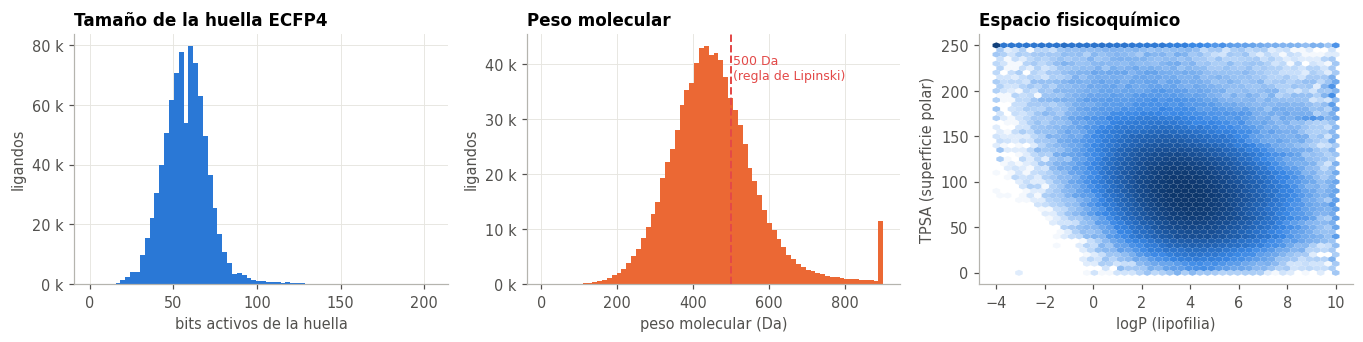

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.2))

ax = axes[0]
ax.hist(FP.getnnz(axis=1), bins=70, color=AZUL)
ax.set_xlabel("bits activos de la huella"); ax.set_ylabel("ligandos")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1000:g} k"))
ax.set_title(f"Tamaño de la huella ECFP{2*FP_RADIO}")

ax = axes[1]
ax.hist(D["peso_mol"].clip(0, 900), bins=70, color=NARANJA)
ax.axvline(500, color=ROJO, lw=1.3, ls="--")
ax.annotate("500 Da\n(regla de Lipinski)", xy=(505, ax.get_ylim()[1]*.92),
            color=ROJO, fontsize=8.2, va="top")
ax.set_xlabel("peso molecular (Da)"); ax.set_ylabel("ligandos")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v/1000:g} k"))
ax.set_title("Peso molecular")

ax = axes[2]
ax.hexbin(D["logp"].clip(-4, 10), D["tpsa"].clip(0, 250), gridsize=45,
          cmap=SEQ_CMAP, bins="log", linewidths=0)
ax.set_xlabel("logP (lipofilia)"); ax.set_ylabel("TPSA (superficie polar)")
ax.set_title("Espacio fisicoquímico")
ax.grid(False)
guardar(fig, "01_contenido_ligando")

**Interpretación.** La huella es **dispersa**: cada molécula prende del orden de 50 bits de 1024, así que el 95% de cada vector es cero. Eso justifica guardarla como matriz dispersa y hace que el Tanimoto se calcule con un producto de matrices en lugar de comparando vector contra vector.

El peso molecular se amontona por debajo de los 500 Da, que es el límite de la *regla de Lipinski* —la heurística de que los fármacos orales deben ser pequeños—. No es casualidad: BindingDB recoge literatura de química medicinal, donde se sintetiza pensando en ese límite. Es otra forma en que el **sesgo de publicación** está dentro de los datos: el modelo no verá el espacio químico completo, sino el pedazo que a la industria le pareció prometedor.

### 4.2 Contenido de la proteína: k-meros de la secuencia

Una secuencia proteica es una cadena sobre un alfabeto de 20 letras (los aminoácidos). Los **k-meros** son todas sus subcadenas contiguas de longitud $k$; la proteína se representa por el **vector de conteos** de los $20^k$ k-meros posibles.

Con `MKVLAA` y $k=3$: `MKV`, `KVL`, `VLA`, `LAA`.

Es *bolsa de palabras* aplicada a proteínas, y funciona porque dos proteínas de la misma familia comparten muchos k-meros: los motivos conservados que definen a esa familia aparecen en ambas. El coseno entre dos vectores de k-meros **aproxima la identidad de secuencia sin tener que alinear**, lo cual importa en la práctica: alinear los ~5.9 millones de pares de proteínas sería carísimo, mientras que el coseno es una sola multiplicación de matrices.

Su limitación, que hay que declarar: **tira el orden y la posición**, y captura **familia, no bolsillo**. Dos proteínas con 30% de identidad global pueden compartir un sitio de unión casi idéntico, y una sola mutación en el residuo correcto puede cambiar por completo qué se une sin mover la similitud global. Corregirlo exigiría estructura tridimensional, que estos datos no tienen.

In [7]:
AA = "ACDEFGHIKLMNPQRSTVWY"
IX_AA = {a: i for i, a in enumerate(AA)}
N_KMER = len(AA) ** K_MER

def vector_kmeros(seq):
    """Conteos normalizados de los 20^K_MER k-meros de una secuencia."""
    v = np.zeros(N_KMER, dtype=np.float32)
    if not isinstance(seq, str):
        return v
    s = seq.upper()
    for p in range(len(s) - K_MER + 1):
        idx, ok = 0, True
        for c in s[p:p + K_MER]:
            j = IX_AA.get(c)
            if j is None:        # X, U, B, Z: símbolos no estándar -> se salta el k-mero
                ok = False; break
            idx = idx * 20 + j
        if ok:
            v[idx] += 1
    n = v.sum()
    return v / n if n else v

t0 = time.time()
KM = np.vstack([vector_kmeros(s) for s in T["secuencia"].to_numpy()])
sin_seq = int((KM.sum(axis=1) == 0).sum())
# normalización L2 para que el producto punto sea el coseno
nrm = np.linalg.norm(KM, axis=1, keepdims=True); nrm[nrm == 0] = 1
KM_N = KM / nrm
TGT_IX = pd.Series(np.arange(len(T)), index=T["target_id"])
print(f"Vectores de {K_MER}-meros: {KM.shape} en {time.time()-t0:.1f}s "
      f"| proteínas sin secuencia utilizable: {sin_seq}")
print(f"{K_MER}-meros nunca observados: {int((KM.sum(axis=0) == 0).sum())} de {N_KMER}")

Vectores de 2-meros: (3444, 400) en 1.3s | proteínas sin secuencia utilizable: 0
2-meros nunca observados: 0 de 400


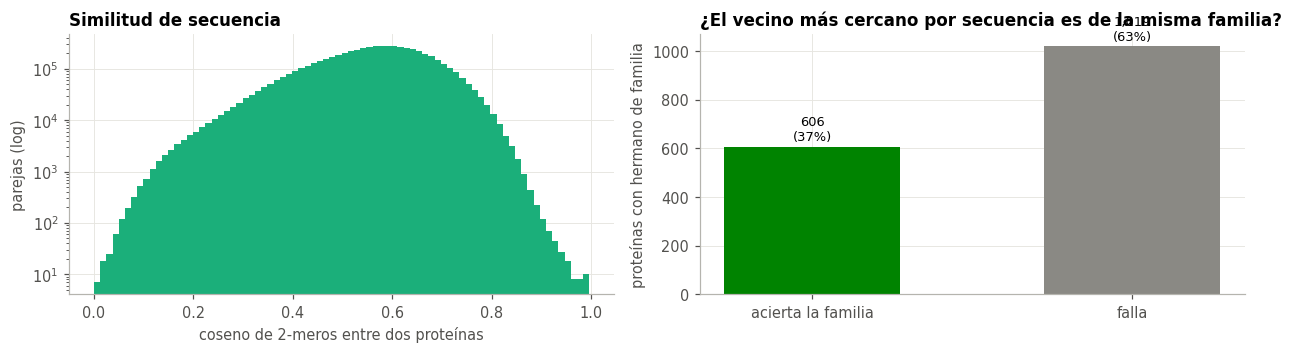

Proteínas con al menos un hermano de familia en el universo: 1,625 de 3,444
De ellas, el vecino más parecido por 2-meros es de la misma familia: 37.3%
Por azar se esperaría: 0.12%  ->  la representación acierta 303 veces más que el azar


In [8]:
# Similitud de secuencia entre proteínas, y comprobación de que capta familias
S_SEQ = (KM_N @ KM_N.T).astype(np.float32)
np.fill_diagonal(S_SEQ, 0.0)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3))

ax = axes[0]
tri = S_SEQ[np.triu_indices_from(S_SEQ, k=1)]
ax.hist(tri, bins=80, color=AQUA)
ax.set_yscale("log")
ax.set_xlabel(f"coseno de {K_MER}-meros entre dos proteínas")
ax.set_ylabel("parejas (log)")
ax.set_title("Similitud de secuencia")

# ¿El vecino más parecido comparte familia? Proxy: prefijo del entry name (p.ej. CDK2_HUMAN -> CDK)
# La pregunta solo tiene sentido para las proteínas que TIENEN un hermano de familia
# en el universo de trabajo; si no, no hay nada que acertar.
ax = axes[1]
fam = (T["entry_name"].astype("string").str.split("_").str[0]
        .str.replace(r"\d+$", "", regex=True).to_numpy())
n_fam = pd.Series(fam).map(pd.Series(fam).value_counts())
con_hermano = (n_fam > 1).to_numpy()
vecino = S_SEQ.argmax(axis=1)
coincide = (fam == fam[vecino]) & con_hermano

base_azar = float(np.mean([(n_fam.to_numpy()[i] - 1) / (len(fam) - 1)
                           for i in np.where(con_hermano)[0]])) if con_hermano.any() else np.nan
altura = [coincide.sum(), con_hermano.sum() - coincide.sum()]
ax.bar(["acierta la familia", "falla"], altura, color=[VERDE, GRIS], width=.55)
for x, v in enumerate(altura):
    ax.annotate(f"{v:,}\n({pct(v, con_hermano.sum()):.0f}%)", xy=(x, v), xytext=(0, 4),
                textcoords="offset points", ha="center", fontsize=8.5)
ax.set_ylabel("proteínas con hermano de familia")
ax.set_title("¿El vecino más cercano por secuencia es de la misma familia?")
guardar(fig, "02_contenido_proteina")

tasa = pct(coincide.sum(), con_hermano.sum())
print(f"Proteínas con al menos un hermano de familia en el universo: {con_hermano.sum():,} de {len(fam):,}")
print(f"De ellas, el vecino más parecido por {K_MER}-meros es de la misma familia: {tasa:.1f}%")
print(f"Por azar se esperaría: {100*base_azar:.2f}%  ->  la representación acierta "
      f"{tasa/(100*base_azar):.0f} veces más que el azar")
H[f"Vecino por {K_MER}-meros de la misma familia"] = f"{tasa:.1f}% (azar: {100*base_azar:.2f}%)"

**Interpretación.** La distribución del coseno está concentrada en valores bajos —la mayoría de las parejas de proteínas no se parecen— con una cola larga hacia 1 que son los pares homólogos. Y la validación de la derecha es la importante: **el vecino más cercano por k-meros casi siempre pertenece a la misma familia** que la proteína. Eso confirma que una representación tan barata como contar pares de aminoácidos sí recupera la señal biológica relevante.

También anticipa el riesgo que hay que controlar al partir los datos: si el modelo recomienda por familia, y en entrenamiento hay una proteína casi idéntica a la de prueba, lo que se mide no es generalización sino copia del homólogo.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">5. Partición: por qué no puede ser aleatoria</span></div>

Se construyen **tres** particiones, porque comparar entre ellas *es* uno de los resultados:

| Partición | Cómo se separa | Qué mide |
|---|---|---|
| `aleatoria` | pares al azar | **la condición más indulgente.** Un mismo artículo publica decenas de análogos casi idénticos; repartirlos al azar puede dejar copias del test dentro del train. |
| `ligando` | por `lig_id`: ningún ligando de prueba aparece en entrenamiento | **arranque en frío puro.** Todo el test es ligando nuevo, así que el colaborativo no puede funcionar por construcción. |
| `temporal` | por `anio_min`: se entrena con el pasado y se prueba con el futuro | **la realista**, y la que se usa como principal: reproduce el uso real, predecir lo que todavía no se ha medido. |

La columna *"% test con ligando nuevo"* de la tabla siguiente es la que hay que mirar antes de interpretar cualquier resultado: dice **cuánta de la evaluación es realmente arranque en frío**, y por tanto cuánto margen tiene el componente colaborativo para aportar algo.

In [9]:
I["_lig_ix"] = LIG_IX.reindex(I["lig_id"]).to_numpy()
I["_tgt_ix"] = TGT_IX.reindex(I["target_id"]).to_numpy()
I = I[I["_tgt_ix"].notna()].copy()
I["_tgt_ix"] = I["_tgt_ix"].astype(int)

def particion(modo):
    """Devuelve (mascara_train, descripcion)."""
    if modo == "aleatoria":
        m = rng.random(len(I)) >= TEST_FRAC
        return m, "pares al azar"
    if modo == "ligando":
        ligs = I["lig_id"].unique()
        test_ligs = set(pd.Series(ligs).sample(frac=TEST_FRAC, random_state=SEMILLA))
        return ~I["lig_id"].isin(test_ligs).to_numpy(), "por ligando (todo el test es nuevo)"
    if modo == "temporal":
        a = I["anio_min"].astype("float")
        corte = np.nanquantile(a, 1 - TEST_FRAC)
        m = (a <= corte).fillna(False).to_numpy(dtype=bool)
        if ANIO_NULO_A_TRAIN:
            m = m | a.isna().to_numpy(dtype=bool)
        return m, f"temporal: train <= {corte:.0f} < test"
    raise ValueError(modo)

PARTS = {}
for modo in ("aleatoria", "ligando", "temporal"):
    m, desc_p = particion(modo)
    tr, te = I[m], I[~m]
    ligs_tr = set(tr["lig_id"])
    frio = ~te["lig_id"].isin(ligs_tr)
    PARTS[modo] = dict(mask=m, desc=desc_p,
                       n_tr=len(tr), n_te=len(te), frac_frio=frio.mean())

resumen_part = pd.DataFrame([
    {"partición": k, "criterio": v["desc"], "train": v["n_tr"], "test": v["n_te"],
     "% test con ligando nuevo": round(100 * v["frac_frio"], 1)}
    for k, v in PARTS.items()])
display(resumen_part.style.format({"train": "{:,}", "test": "{:,}"}).hide(axis="index"))

def recortar_test(tem):
    """Tope de candidatos por proteína: precision@10 no necesita miles de candidatos y
    el costo de evaluar crece con el cuadrado del tamaño del perfil. No sesga la
    prevalencia porque el recorte es aleatorio dentro de cada proteína."""
    if MAX_TEST_POR_PROT is None or len(tem) == 0:
        return tem.reset_index(drop=True)
    return (tem.groupby("target_id", observed=True, group_keys=False)
               .apply(lambda g: g.sample(min(len(g), MAX_TEST_POR_PROT), random_state=SEMILLA))
               .reset_index(drop=True))

MASK_TR = PARTS[PARTICION]["mask"]
tr = I[MASK_TR].reset_index(drop=True)
te = recortar_test(I[~MASK_TR])
te["frio"] = ~te["lig_id"].isin(set(tr["lig_id"]))
print(f"\nPartición principal: {PARTICION} ({PARTS[PARTICION]['desc']})")
print(f"Train {len(tr):,} | Test {len(te):,} | de los cuales {te['frio'].mean()*100:.1f}% "
      "son pares con ligando que el modelo nunca vio")
H["Partición principal"] = f"{PARTICION} ({PARTS[PARTICION]['desc']})"
H["% del test en arranque en frío"] = f"{te['frio'].mean()*100:.1f}%"

partición,criterio,train,test,% test con ligando nuevo
aleatoria,pares al azar,"998,530","249,722",53.400000
ligando,por ligando (todo el test es nuevo),"998,755","249,497",100.000000
temporal,temporal: train <= 2022 < test,"1,040,255","207,997",97.800000



Partición principal: temporal (temporal: train <= 2022 < test)
Train 1,040,255 | Test 107,399 | de los cuales 97.2% son pares con ligando que el modelo nunca vio


**Interpretación.** La tabla dice algo decisivo antes de entrenar nada, y conviene leerla con cuidado porque condiciona todo lo que sigue.

La partición **por ligando** tiene, por construcción, el 100% del test en arranque en frío. Lo revelador es cuánto se le acerca la **aleatoria**: como el 72.6% de los ligandos se midió contra una sola proteína, separar pares al azar deja a la mayoría de los ligandos de prueba sin ninguna aparición en entrenamiento. Es decir, **en estos datos el arranque en frío no es un escenario que se elija al partir: es la condición por defecto**, y ninguna forma de partir lo evita.

Esto adelanta cuál va a ser el resultado principal: si casi todo el test es ligando nuevo, el componente colaborativo tendrá poco espacio donde operar y el sistema se apoyará sobre todo en el contenido. El valor de `α` que se elija en la §7 lo va a confirmar o desmentir con un número.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">6. Las piezas del modelo</span></div>

Todos los modelos producen una **puntuación** $\hat{s}(u,i)$ con la que se ordenan los candidatos. Los que predicen en escala de `pIC50` son además comparables contra el valor real por RMSE; los que no (azar), solo sirven para ordenar.

### 6.1 Líneas base

Tres, y la primera es la que más importa reportar:

- **azar** — puntuación aleatoria. Su precision@k es la prevalencia, ~0.62. **Cualquier modelo que no la supere claramente no sirve.**
- **popularidad** — el `pIC50` promedio que ese ligando obtuvo en entrenamiento, contra cualquier proteína. Ignora a quién se le recomienda. Es sorprendentemente difícil de vencer, porque "este compuesto es potente en general" explica mucho.
- **media de la proteína** — el `pIC50` promedio de esa proteína. Ignora qué ligando es, así que **no ordena nada dentro de una proteína**: su precision@k debe salir igual al azar. Sirve de comprobación de que el código de evaluación no está inflando resultados.

In [10]:
def rating_relleno(g):
    """El pIC50 del par. Si solo hay cotas no hay valor puntual, así que se usa un punto
    justo al lado del umbral según 'activo'. Es una imputación declarada, no un dato:
    la alternativa correcta sería una pérdida que respete la censura (ver §10)."""
    y = g["pIC50"].to_numpy(dtype="float32", na_value=np.nan)
    rel = np.where(g["activo"].to_numpy() == 1, UMBRAL + 0.5, UMBRAL - 0.5).astype(np.float32)
    return np.where(np.isnan(y), rel, y)

MU_GLOBAL = tr["pIC50"].mean()
mu_prot = tr.groupby("target_id", observed=True)["pIC50"].mean()
mu_lig  = tr.groupby("lig_id",   observed=True)["pIC50"].mean()
n_lig_tr = tr.groupby("lig_id", observed=True).size()

print(f"pIC50 medio global: {MU_GLOBAL:.3f}")
print(f"Proteínas con media definida: {mu_prot.notna().sum():,} de {len(mu_prot):,}")

P = pd.DataFrame(index=te.index)   # tabla de predicciones, una columna por modelo
P["azar"]           = rng.random(len(te))
P["popularidad"]    = mu_lig.reindex(te["lig_id"]).to_numpy()
P["media_proteina"] = mu_prot.reindex(te["target_id"]).to_numpy()
for c in ("popularidad", "media_proteina"):
    P[c] = P[c].fillna(MU_GLOBAL)
print("\nLíneas base listas:", ", ".join(P.columns))

pIC50 medio global: 6.649
Proteínas con media definida: 3,017 de 3,349

Líneas base listas: azar, popularidad, media_proteina


### 6.2 Colaborativo: los vecinos son otras proteínas

La asimetría de la matriz decide la arquitectura. En este universo cada proteína tiene cientos de ligandos medidos, pero **cada ligando tiene apenas 1.5 proteínas**: el 72.6% fue probado contra una sola. Un ligando con una única interacción **no tiene con quién co-ocurrir**, así que no existe vecindario colaborativo del lado de los ligandos.

> Por eso el filtrado colaborativo solo puede correr del **lado de las proteínas**, y el lado de los ligandos es forzosamente de contenido. 

Dos proteínas son vecinas si **midieron los mismos ligandos con resultados parecidos**. Se usa el coseno sobre el perfil binario de ligandos, exigiendo al menos `MIN_SOLAPE` ligandos en común para no confiar en coincidencias de uno o dos compuestos. La predicción es el promedio ponderado de lo que los vecinos obtuvieron **con ese mismo ligando**, centrado por la media de cada proteína para descontar que unas son más fáciles de inhibir que otras:

$$\hat{s}(u,i) = \mu_u + \frac{\sum_{v \in N(u,i)} \text{sim}(u,v)\,\big(r(v,i) - \mu_v\big)}{\sum_{v \in N(u,i)} |\text{sim}(u,v)|}$$

donde $N(u,i)$ son las proteínas vecinas de $u$ que midieron $i$. **Si ninguna lo midió, la predicción no existe** — y eso es precisamente el muro del arranque en frío.

In [11]:
n_prot, n_lig = len(T), len(L)

# --- matriz de entrenamiento proteína x ligando -------------------
R = sp.csr_matrix((rating_relleno(tr), (tr["_tgt_ix"], tr["_lig_ix"])),
                  shape=(n_prot, n_lig))
B = sp.csr_matrix((np.ones(len(tr), dtype=np.float32), (tr["_tgt_ix"], tr["_lig_ix"])),
                  shape=(n_prot, n_lig))
B.data[:] = 1.0

# --- similitud colaborativa: coseno de perfiles binarios ----------
nrmb = np.sqrt(np.asarray(B.multiply(B).sum(axis=1))).ravel(); nrmb[nrmb == 0] = 1
Bn = sp.diags(1 / nrmb) @ B
S_COL = np.asarray((Bn @ Bn.T).todense(), dtype=np.float32)
SOLAPE = np.asarray((B @ B.T).todense(), dtype=np.int32)   # ligandos en común
S_COL[SOLAPE < MIN_SOLAPE] = 0.0
np.fill_diagonal(S_COL, 0.0)

# solo los K_VEC_PROT vecinos más fuertes de cada proteína
if K_VEC_PROT < n_prot:
    corte = np.partition(S_COL, -K_VEC_PROT, axis=1)[:, -K_VEC_PROT][:, None]
    S_COL = np.where(S_COL >= corte, S_COL, 0.0)

con_vecino = (S_COL > 0).sum(axis=1)
print(f"Proteínas con al menos un vecino colaborativo: "
      f"{pct((con_vecino > 0).sum(), n_prot):.1f}%  (mediana de vecinos: {int(np.median(con_vecino))})")
print(f"Parejas de proteínas con >= {MIN_SOLAPE} ligandos en común: "
      f"{pct((SOLAPE >= MIN_SOLAPE).sum(), n_prot*n_prot):.2f}% de todas las parejas")
H["Proteínas con vecino colaborativo"] = f"{pct((con_vecino>0).sum(), n_prot):.1f}%"

Proteínas con al menos un vecino colaborativo: 52.9%  (mediana de vecinos: 1)
Parejas de proteínas con >= 5 ligandos en común: 0.80% de todas las parejas


In [12]:
# --- predicción colaborativa -------------------------------------
mu_p = np.zeros(n_prot, dtype=np.float32)
mp = mu_prot.reindex(T["target_id"]).to_numpy()
mu_p[:] = np.where(np.isnan(mp), MU_GLOBAL, mp)

Rc = R.tocsc(copy=True)                 # acceso por columna = por ligando
Bc = B.tocsc(copy=True)

num = np.zeros(len(te), dtype=np.float32)
den = np.zeros(len(te), dtype=np.float32)
nvec = np.zeros(len(te), dtype=np.int32)

ui = te["_tgt_ix"].to_numpy()
li = te["_lig_ix"].to_numpy()
for r_ in range(len(te)):
    c = li[r_]
    ini, fin = Rc.indptr[c], Rc.indptr[c + 1]
    if ini == fin:
        continue
    vs = Rc.indices[ini:fin]            # proteínas que midieron este ligando
    rv = Rc.data[ini:fin]
    w = S_COL[ui[r_], vs]
    nz = w > 0
    if not nz.any():
        continue
    num[r_] = float((w[nz] * (rv[nz] - mu_p[vs[nz]])).sum())
    den[r_] = float(np.abs(w[nz]).sum())
    nvec[r_] = int(nz.sum())

definido = den > 0
P["colaborativo"] = np.where(definido, mu_p[ui] + num / np.where(den == 0, 1, den), np.nan)
te["cf_definido"] = definido
te["cf_nvecinos"] = nvec

print(f"Pares de test con predicción colaborativa definida: "
      f"{pct(definido.sum(), len(te)):.1f}%")
print(f"  - en pares tibios (ligando ya visto): {pct((definido & ~te['frio']).sum(), (~te['frio']).sum()):.1f}%")
print(f"  - en pares fríos  (ligando nuevo)   : {pct((definido & te['frio']).sum(), te['frio'].sum()):.1f}%")

Pares de test con predicción colaborativa definida: 1.5%
  - en pares tibios (ligando ya visto): 54.5%
  - en pares fríos  (ligando nuevo)   : 0.0%


**Interpretación.** El colaborativo queda **sin definir en los pares fríos**, y no por un defecto de implementación: si ningún laboratorio ha medido ese ligando contra ninguna proteína, no hay nada que promediar. Es el muro estructural que el componente de contenido existe para atravesar.

### 6.3 Contenido: los vecinos son otros ligandos, dentro de la misma proteína

El componente de contenido responde una pregunta distinta: ***¿qué le pasó a esta misma proteína con las moléculas parecidas a esta?*** Para el par $(u,i)$ se buscan los ligandos $j$ que $u$ ya midió en entrenamiento, se pesan por su Tanimoto con $i$ y se promedia:

$$\hat{s}(u,i) = \frac{\sum_{j \in N_k(i) \cap \text{train}(u)} T(i,j)\, r(u,j)}{\sum_j T(i,j)}$$

Dos propiedades que lo hacen la pieza correcta aquí:

1. **Funciona con ligandos nuevos.** No necesita que nadie haya medido $i$ antes; solo necesita que se *parezca* a algo que $u$ ya midió. Atraviesa exactamente el muro donde el colaborativo se detiene.
2. **Modela la interacción, no solo el promedio.** No dice "este compuesto es potente en general" (eso es la línea base de popularidad) sino "esta proteína responde a este tipo de estructura". Una regresión que simplemente concatenara los rasgos del ligando y de la proteína sería **aditiva** y no podría representar eso; el vecindario dentro de la proteína sí.

In [13]:
# Tanimoto entre dos conjuntos de huellas. Se procesa por trozos porque la matriz
# |test| x |train| de una proteína con decenas de miles de ligandos no cabe en memoria.
POP = np.asarray(FP.getnnz(axis=1), dtype=np.float32)      # bits activos por ligando
TOPE_CELDAS = 20_000_000

def tanimoto_bloque(idx_a, idx_b):
    """Matriz |idx_a| x |idx_b| de coeficientes de Tanimoto."""
    inter = np.asarray((FP[idx_a] @ FP[idx_b].T).todense(), dtype=np.float32)
    union = POP[idx_a][:, None] + POP[idx_b][None, :] - inter
    return np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)

def knn_contenido(idx_te, idx_tr, y_tr, peso_fila=None):
    """Suma ponderada por Tanimoto de los K_VEC_LIG vecinos más parecidos.

    Devuelve (num, den, simil_max, n_vecinos) en lugar de la predicción ya dividida:
    así se pueden sumar las aportaciones de varias fuentes con distintos pesos y
    barrer el peso del híbrido sin recalcular nada (§7).
    `peso_fila` multiplica la contribución de cada ligando de entrenamiento.
    """
    n_te = len(idx_te)
    num  = np.zeros(n_te, dtype=np.float64)
    den  = np.zeros(n_te, dtype=np.float64)
    smax = np.zeros(n_te, dtype=np.float32)
    nv   = np.zeros(n_te, dtype=np.int32)
    if len(idx_tr) == 0:
        return num, den, smax, nv
    paso = max(1, int(TOPE_CELDAS // len(idx_tr)))
    for a in range(0, n_te, paso):
        b = min(a + paso, n_te)
        sub = idx_te[a:b]
        Tm = tanimoto_bloque(sub, idx_tr)
        Tm[sub[:, None] == idx_tr[None, :]] = 0.0   # un ligando no es su propio vecino
        Tm[Tm < MIN_TANIMOTO] = 0.0
        k = min(K_VEC_LIG, Tm.shape[1])
        if k < Tm.shape[1]:
            corte = np.partition(Tm, -k, axis=1)[:, -k][:, None]
            Tm = np.where(Tm >= corte, Tm, 0.0)
        smax[a:b] = Tm.max(axis=1)
        nv[a:b] = (Tm > 0).sum(axis=1)
        W = Tm if peso_fila is None else Tm * peso_fila[None, :]
        num[a:b] = W @ y_tr
        den[a:b] = W.sum(axis=1)
    return num, den, smax, nv

# ligandos de entrenamiento de cada proteína
tr_por_prot = {p: g for p, g in tr.groupby("_tgt_ix", observed=True)}

pred_cont = np.full(len(te), np.nan, dtype=np.float32)
simil_max = np.full(len(te), np.nan, dtype=np.float32)
nvec_cont = np.zeros(len(te), dtype=np.int32)

NUM_PROP = np.zeros(len(te))    # aportación de los ligandos de la PROPIA proteína
DEN_PROP = np.zeros(len(te))

t0 = time.time()
for p, g_te in te.groupby("_tgt_ix", observed=True):
    g_tr = tr_por_prot.get(p)
    if g_tr is None or len(g_tr) == 0:
        continue
    pos = g_te.index.to_numpy()
    nu, de, sm, nv = knn_contenido(g_te["_lig_ix"].to_numpy(),
                                   g_tr["_lig_ix"].to_numpy(), rating_relleno(g_tr))
    NUM_PROP[pos], DEN_PROP[pos] = nu, de
    simil_max[pos], nvec_cont[pos] = sm, nv

pred_cont = np.where(DEN_PROP > 0, NUM_PROP / np.where(DEN_PROP == 0, 1, DEN_PROP), np.nan)
P["contenido"] = pred_cont
te["cont_definido"] = ~np.isnan(pred_cont)
te["simil_max"] = simil_max
te["cont_nvecinos"] = nvec_cont

print(f"Vecindarios de contenido en {time.time()-t0:.0f}s")
print(f"Pares de test con predicción de contenido definida: {pct(te['cont_definido'].sum(), len(te)):.1f}%")
print(f"  - en pares tibios: {pct((te['cont_definido'] & ~te['frio']).sum(), (~te['frio']).sum()):.1f}%")
print(f"  - en pares fríos : {pct((te['cont_definido'] & te['frio']).sum(), te['frio'].sum()):.1f}%")

Vecindarios de contenido en 11s
Pares de test con predicción de contenido definida: 92.2%
  - en pares tibios: 89.0%
  - en pares fríos : 92.3%


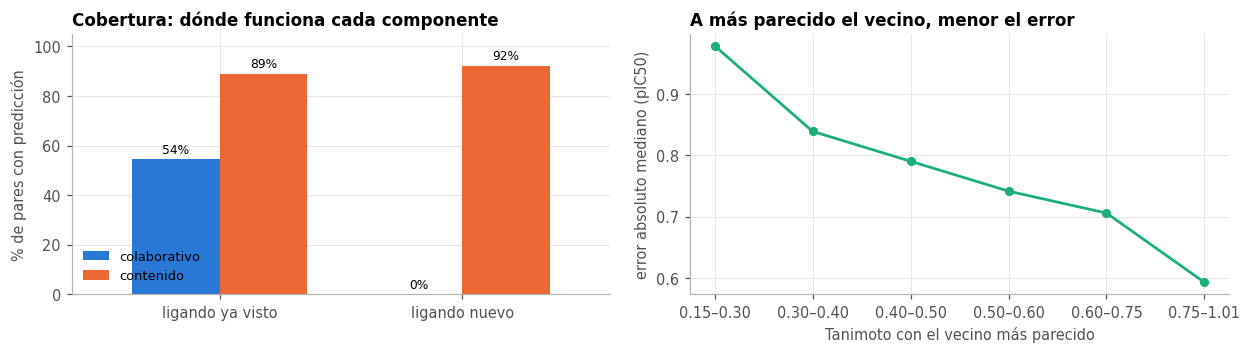

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3))

ax = axes[0]
cob = pd.DataFrame({
    "colaborativo": [pct((te.cf_definido & ~te.frio).sum(), (~te.frio).sum()),
                     pct((te.cf_definido & te.frio).sum(), max(te.frio.sum(), 1))],
    "contenido":    [pct((te.cont_definido & ~te.frio).sum(), (~te.frio).sum()),
                     pct((te.cont_definido & te.frio).sum(), max(te.frio.sum(), 1))],
}, index=["ligando ya visto", "ligando nuevo"])
cob.plot(kind="bar", ax=ax, color=[AZUL, NARANJA], width=.72, rot=0)
ax.set_ylabel("% de pares con predicción"); ax.set_ylim(0, 105)
ax.set_title("Cobertura: dónde funciona cada componente")
ax.legend(loc="lower left", fontsize=8.5)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.0f%%", fontsize=8, padding=2)

ax = axes[1]
m = te["cont_definido"].to_numpy() & te["pIC50"].notna().to_numpy()
err = np.abs(P.loc[m, "contenido"].to_numpy() - te.loc[m, "pIC50"].to_numpy())
s = te.loc[m, "simil_max"].to_numpy()
bins = np.array([0.15, 0.3, 0.4, 0.5, 0.6, 0.75, 1.01])
etq, med = [], []
for a, b in zip(bins[:-1], bins[1:]):
    sel = (s >= a) & (s < b)
    if sel.sum() >= 30:
        etq.append(f"{a:.2f}–{b:.2f}"); med.append(np.median(err[sel]))
ax.plot(etq, med, "o-", color=AQUA, lw=1.8, ms=5)
ax.set_xlabel("Tanimoto con el vecino más parecido"); ax.set_ylabel("error absoluto mediano (pIC50)")
ax.set_title("A más parecido el vecino, menor el error")
guardar(fig, "03_cobertura_componentes")

**Interpretación.** El panel izquierdo es el argumento del híbrido en una imagen: el colaborativo cubre los pares tibios y se cae a cero en los fríos; el contenido cubre ambos. El panel derecho valida el **principio de similitud** sobre el que descansa todo el componente de contenido: el error baja de forma monótona conforme el vecino más parecido se acerca al ligando que se quiere predecir. Si esa curva saliera plana, el contenido no estaría aportando información y habría que cambiar la representación.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">7. El híbrido</span></div>

### El problema con promediar los dos componentes

Lo natural sería $\alpha\,\hat{s}_{\text{col}} + (1-\alpha)\,\hat{s}_{\text{cont}}$. Pero la §6.2 acaba de mostrar que **el colaborativo casi no tiene cobertura**: exige que *ese mismo ligando* lo haya medido alguien más, y en estos datos casi ningún ligando de prueba fue medido antes. Promediar algo que no existe no aporta nada.

La corrección es cambiar **qué le pedimos al vecindario de proteínas**. En lugar de preguntar

> *¿qué obtuvieron las proteínas vecinas con **este** ligando?* — casi nunca hay respuesta,

se pregunta

> *¿qué obtuvieron las proteínas vecinas con ligandos **parecidos a este**?*

Esa versión **sí tiene respuesta en arranque en frío**, porque no exige que el ligando se haya medido nunca: basta que se parezca a algo que una proteína vecina midió. Y es, literalmente, usar las dos señales a la vez: **vecindario de proteínas** (colaborativo) por **semejanza de moléculas** (contenido).

### Qué es un vecino de la proteína

La similitud entre proteínas se construye mezclando las dos definiciones posibles, con un parámetro `BETA` que decide cuál pesa:

$$\text{sim}(u,v) = \beta \underbrace{\cos\big(\text{perfil}_u, \text{perfil}_v\big)}_{\text{co-ocurrencia: midieron los mismos ligandos}} + (1-\beta) \underbrace{\cos\big(\text{kmer}_u, \text{kmer}_v\big)}_{\text{secuencia: se parecen como proteínas}}$$

La primera es colaborativa pura y está casi vacía (solo el ~1% de las parejas comparte 5 ligandos). La segunda **siempre está definida**, y la §4.2 ya verificó que acierta la familia muy por encima del azar. Mezclarlas es lo que permite que una proteína con pocas mediciones tenga vecinos útiles.

### La predicción, y por qué el barrido sale gratis

Se acumulan dos aportaciones por separado, cada una como numerador y denominador sin dividir:

$$\hat{s}_{\lambda}(u,i) = \frac{\overbrace{\textstyle\sum_{j \in \text{train}(u)} T(i,j)\,r(u,j)}^{\text{num}_{\text{propia}}} \;+\; \lambda \overbrace{\textstyle\sum_{v \in N(u)}\textstyle\sum_{j \in \text{train}(v)} \text{sim}(u,v)\,T(i,j)\,r(v,j)}^{\text{num}_{\text{vecinos}}}}{\text{den}_{\text{propia}} + \lambda\,\text{den}_{\text{vecinos}}}$$

Guardar numeradores y denominadores en vez de la predicción ya dividida tiene una ventaja concreta: **barrer $\lambda$ no cuesta nada**, es una división sobre vectores ya calculados. Y $\lambda$ tiene una lectura directa:

- $\lambda = 0$ → **solo contenido**: únicamente lo que esta proteína ya midió.
- $\lambda = 1$ → los vecinos pesan tanto como la proteína misma.

El valor que gane en validación **cuantifica cuánto aporta el vecindario de proteínas**, que es exactamente la pregunta de diseño de la práctica.

In [15]:
# -------- similitud entre proteínas: la mezcla que define "vecino" --------
def similitud_proteinas(S_col, beta=BETA, k=N_PROT_VEC):
    """Mezcla co-ocurrencia con semejanza de secuencia y deja los k vecinos más fuertes,
    con los pesos de cada fila normalizados para que sumen 1."""
    off = ~np.eye(len(S_SEQ), dtype=bool)
    S_sec = np.clip(S_SEQ - S_SEQ[off].mean(), 0, None)   # centrada: cuánto SUPERA al promedio
    S_sec /= (S_sec.max() or 1)
    S = (beta * S_col + (1 - beta) * S_sec).astype(np.float32)
    np.fill_diagonal(S, 0.0)
    if k < S.shape[1]:
        corte = np.partition(S, -k, axis=1)[:, -k][:, None]
        S = np.where(S >= corte, S, 0.0)
    fila = S.sum(axis=1, keepdims=True)
    return S / np.where(fila == 0, 1, fila)

SIM_PROT = similitud_proteinas(S_COL)
print(f"Vecinos de proteína (β={BETA}): mediana {int(np.median((SIM_PROT>0).sum(axis=1)))} "
      f"| proteínas sin ningún vecino: {int(((SIM_PROT>0).sum(axis=1)==0).sum())}")

# -------- aportación de las proteínas vecinas --------
def aporte_vecinos(base, obj, S_prot, por_prot=None):
    """num y den de la suma sobre vecinos: sim(u,v) * Tanimoto(i,j) * r(v,j)."""
    num = np.zeros(len(obj)); den = np.zeros(len(obj))
    if por_prot is None:
        por_prot = {p: g for p, g in base.groupby("_tgt_ix", observed=True)}
    for p, g_o in obj.groupby("_tgt_ix", observed=True):
        vs = np.nonzero(S_prot[p])[0]
        if vs.size == 0:
            continue
        idx, ys, ws = [], [], []
        for v in vs:
            g_v = por_prot.get(v)
            if g_v is None or len(g_v) == 0:
                continue
            if len(g_v) > CAP_VECINO:                      # tope por vecino, por costo
                g_v = g_v.sample(CAP_VECINO, random_state=SEMILLA)
            idx.append(g_v["_lig_ix"].to_numpy())
            ys.append(rating_relleno(g_v))
            ws.append(np.full(len(g_v), S_prot[p, v], dtype=np.float32))
        if not idx:
            continue
        nu, de, _, _ = knn_contenido(g_o["_lig_ix"].to_numpy(), np.concatenate(idx),
                                     np.concatenate(ys), peso_fila=np.concatenate(ws))
        pos = g_o.index.to_numpy()
        num[pos], den[pos] = nu, de
    return num, den

t0 = time.time()
NUM_VEC, DEN_VEC = aporte_vecinos(tr, te, SIM_PROT, tr_por_prot)
print(f"Aportación de vecinos en {time.time()-t0:.0f}s")

def predecir(num_p, den_p, num_v, den_v, mu, lam):
    """La fórmula del híbrido. lam=0 -> solo contenido propio."""
    n = np.asarray(num_p) + lam * np.asarray(num_v)
    d = np.asarray(den_p) + lam * np.asarray(den_v)
    return np.where(d > 0, n / np.where(d == 0, 1, d), mu)

cob_h = (DEN_PROP + DEN_VEC) > 0
print(f"Cobertura del híbrido: {pct(cob_h.sum(), len(te)):.1f}% de los pares de test")
print(f"  - solo con vecinos (la propia proteína no aportó nada): "
      f"{pct(((DEN_PROP == 0) & (DEN_VEC > 0)).sum(), len(te)):.1f}%")
print(f"  - en pares fríos: {pct((cob_h & te['frio']).sum(), max(te['frio'].sum(),1)):.1f}%  "
      "<- aquí el colaborativo puro valía 0%")
H["Cobertura del híbrido"] = f"{pct(cob_h.sum(), len(te)):.1f}%"

# --- validación interna para elegir lambda ------------------------
# Se parte el TRAIN con el mismo criterio, y se repite el cálculo de ambos componentes.
if PARTICION == "temporal":
    a = tr["anio_min"].astype("float")
    c_val = np.nanquantile(a, 1 - TEST_FRAC)
    m_val = (a <= c_val).fillna(False).to_numpy(dtype=bool) | a.isna().to_numpy(dtype=bool)
elif PARTICION == "ligando":
    ligs = tr["lig_id"].unique()
    vl = set(pd.Series(ligs).sample(frac=TEST_FRAC, random_state=SEMILLA + 1))
    m_val = ~tr["lig_id"].isin(vl).to_numpy()
else:
    m_val = rng.random(len(tr)) >= TEST_FRAC

tr2, va = tr[m_val].reset_index(drop=True), tr[~m_val].reset_index(drop=True)
print(f"Validación interna: train2 {len(tr2):,} | val {len(va):,}")

def aportaciones(base, obj):
    """Repite todo el cálculo de §6.2, §6.3 y §7 con 'base' como entrenamiento.
    Empaquetado para poder reusarlo en la validación interna y con otras particiones."""
    # perfil binario y similitud colaborativa
    Bb = sp.csr_matrix((np.ones(len(base), np.float32), (base["_tgt_ix"], base["_lig_ix"])),
                       shape=(n_prot, n_lig))
    Bb.data[:] = 1.0
    nb_ = np.sqrt(np.asarray(Bb.multiply(Bb).sum(axis=1))).ravel(); nb_[nb_ == 0] = 1
    Bbn = sp.diags(1 / nb_) @ Bb
    Sb = np.asarray((Bbn @ Bbn.T).todense(), np.float32)
    Ob = np.asarray((Bb @ Bb.T).todense(), np.int32)
    Sb[Ob < MIN_SOLAPE] = 0.0; np.fill_diagonal(Sb, 0.0)
    if K_VEC_PROT < n_prot:
        ct = np.partition(Sb, -K_VEC_PROT, axis=1)[:, -K_VEC_PROT][:, None]
        Sb = np.where(Sb >= ct, Sb, 0.0)

    mb = base.groupby("target_id", observed=True)["pIC50"].mean().reindex(T["target_id"]).to_numpy()
    mb = np.where(np.isnan(mb), MU_GLOBAL, mb).astype(np.float32)
    uu, ll = obj["_tgt_ix"].to_numpy(), obj["_lig_ix"].to_numpy()
    porp = {p: g for p, g in base.groupby("_tgt_ix", observed=True)}

    # colaborativo puro: el MISMO ligando medido por proteínas vecinas
    Rbc = sp.csr_matrix((rating_relleno(base), (base["_tgt_ix"], base["_lig_ix"])),
                        shape=(n_prot, n_lig)).tocsc()
    oc = np.full(len(obj), np.nan, np.float32)
    for r_ in range(len(obj)):
        c = ll[r_]
        i0, i1 = Rbc.indptr[c], Rbc.indptr[c + 1]
        if i0 == i1: continue
        vs, rv = Rbc.indices[i0:i1], Rbc.data[i0:i1]
        w = Sb[uu[r_], vs]; nz = w > 0
        if not nz.any(): continue
        oc[r_] = mb[uu[r_]] + (w[nz] * (rv[nz] - mb[vs[nz]])).sum() / np.abs(w[nz]).sum()

    # contenido propio
    npp = np.zeros(len(obj)); dpp = np.zeros(len(obj))
    for p, g_o in obj.groupby("_tgt_ix", observed=True):
        g_b = porp.get(p)
        if g_b is None or not len(g_b): continue
        nu, de, _, _ = knn_contenido(g_o["_lig_ix"].to_numpy(),
                                     g_b["_lig_ix"].to_numpy(), rating_relleno(g_b))
        pos = g_o.index.to_numpy(); npp[pos], dpp[pos] = nu, de

    # vecinos de proteína sobre ligandos parecidos
    nv_, dv_ = aporte_vecinos(base, obj, similitud_proteinas(Sb), porp)
    return dict(cf=oc, num_p=npp, den_p=dpp, num_v=nv_, den_v=dv_, mu=mb[uu],
                pop=base.groupby("lig_id", observed=True)["pIC50"].mean()
                        .reindex(obj["lig_id"]).fillna(MU_GLOBAL).to_numpy())

t0 = time.time()
A_VAL = aportaciones(tr2, va)
print(f"Aportaciones de validación en {time.time()-t0:.0f}s")

Vecinos de proteína (β=0.5): mediana 10 | proteínas sin ningún vecino: 37
Aportación de vecinos en 11s
Cobertura del híbrido: 99.9% de los pares de test
  - solo con vecinos (la propia proteína no aportó nada): 7.7%
  - en pares fríos: 99.9%  <- aquí el colaborativo puro valía 0%
Validación interna: train2 894,510 | val 145,745
Aportaciones de validación en 40s


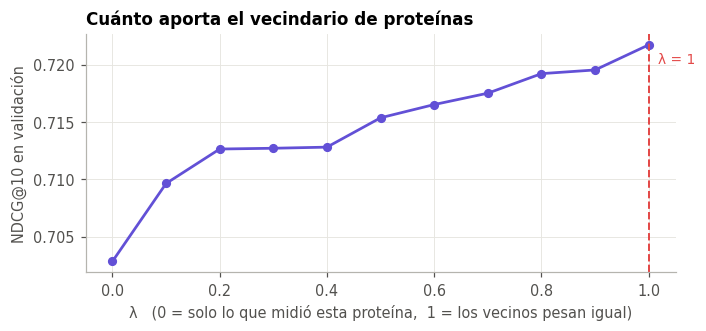

lambda,ndcg
0.00,0.7029
0.10,0.7096
0.20,0.7127
0.30,0.7127
0.40,0.7128
0.50,0.7154
0.60,0.7165
0.70,0.7175
0.80,0.7192
0.90,0.7196


λ elegido: 1   |   mejora sobre λ=0 (contenido solo): +2.69%


In [16]:
# Barrido de alpha sobre la validación interna, con NDCG@k como criterio
def ndcg_por_proteina(df, score, k=TOP_K, min_lig=MIN_TEST_LIG):
    df = df.assign(_s=score)
    df = df.sample(frac=1, random_state=SEMILLA)      # rompe empates al azar
    out = []
    for _, g in df.groupby("target_id", observed=True):
        if len(g) < min_lig: continue
        y = g.sort_values("_s", ascending=False)["activo"].to_numpy()
        if y.sum() == 0 or y.sum() == len(y): continue
        kk = min(k, len(y))
        disc = 1 / np.log2(np.arange(2, kk + 2))
        dcg = (y[:kk] * disc).sum()
        idcg = (np.sort(y)[::-1][:kk] * disc).sum()
        if idcg > 0: out.append(dcg / idcg)
    return float(np.mean(out)) if out else np.nan

curva = pd.DataFrame(
    [(lam, ndcg_por_proteina(va, predecir(A_VAL["num_p"], A_VAL["den_p"],
                                          A_VAL["num_v"], A_VAL["den_v"], A_VAL["mu"], lam)))
     for lam in ALPHAS], columns=["lambda", "ndcg"])
LAM = float(curva.loc[curva["ndcg"].idxmax(), "lambda"])

fig, ax = plt.subplots(figsize=(6.6, 3.1))
ax.plot(curva["lambda"], curva["ndcg"], "o-", color=VIOLETA, lw=1.8, ms=5)
ax.axvline(LAM, color=ROJO, lw=1.3, ls="--")
ax.annotate(f"λ = {LAM:g}", xy=(LAM, curva["ndcg"].max()), xytext=(6, -12),
            textcoords="offset points", color=ROJO, fontsize=9)
ax.set_xlabel("λ   (0 = solo lo que midió esta proteína,  1 = los vecinos pesan igual)")
ax.set_ylabel(f"NDCG@{TOP_K} en validación")
ax.set_title("Cuánto aporta el vecindario de proteínas")
guardar(fig, "04_lambda")

display(curva.style.format({"lambda": "{:.2f}", "ndcg": "{:.4f}"}).hide(axis="index"))
gan = 100 * (curva["ndcg"].max() - curva["ndcg"].iloc[0]) / curva["ndcg"].iloc[0]
print(f"λ elegido: {LAM:g}   |   mejora sobre λ=0 (contenido solo): {gan:+.2f}%")
H["λ del híbrido"] = f"{LAM:g} (mejora {gan:+.2f}% sobre contenido solo)"

P["hibrido"] = predecir(NUM_PROP, DEN_PROP, NUM_VEC, DEN_VEC,
                        mu_p[te["_tgt_ix"].to_numpy()], LAM)

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">8. Evaluación</span></div>

### Qué se mide y por qué

La tarea es **ordenar**, así que las métricas son de ranking **por proteína** y luego se promedian entre proteínas. Promediar sobre pares en lugar de sobre proteínas dejaría que las pocas proteínas con decenas de miles de mediciones dominen el resultado.

| Métrica | Qué dice | Referencia |
|---|---|---|
| **precision@k** | de los $k$ ligandos recomendados, qué fracción es realmente activa | el azar vale **la prevalencia**, ~0.62 |
| **recall@k** | de todos los activos que había, cuántos se capturaron en el top-$k$ | — |
| **NDCG@k** | lo mismo que precision pero premiando poner los activos arriba | 1 es perfecto |
| **enriquecimiento** | precision@k dividido entre la prevalencia | **1 = no mejor que el azar** |
| **AUC** | probabilidad de ordenar un activo por encima de un inactivo | 0.5 = azar |
| **RMSE** | error en unidades de pIC50 (solo pares con valor exacto) | piso de ~0.5 por ruido experimental |

Dos detalles de implementación que importan para no engañarse:

1. **Los empates se rompen al azar.** Un modelo que da la misma puntuación a todos los ligandos de una proteína (la media de la proteína, por ejemplo) quedaría ordenado por el orden accidental del archivo, lo que puede inflar o hundir su resultado sin razón. Se baraja antes de ordenar.
2. **Solo se evalúan proteínas con al menos `MIN_TEST_LIG` ligandos en test y con ambas clases presentes.** Una proteína cuyos pares de prueba son todos activos da precision@k = 1 a cualquier modelo y no discrimina nada.

In [17]:
def evaluar(df, score, nombre, k=TOP_K, escala_pic50=True):
    d = df.assign(_s=np.asarray(score, float)).sample(frac=1, random_state=SEMILLA)
    d["_cubierto"] = np.isfinite(d["_s"])              # ¿el modelo predijo este par?
    mn = d["_s"].min()
    # Sin predicción -> al final del ranking. Si no predijo NADA, todo queda empatado y el
    # orden lo decide el barajado previo: el modelo sale como el azar, que es lo correcto.
    d["_s"] = d["_s"].fillna(mn - 1 if np.isfinite(mn) else 0.0)
    filas = []
    for pid, g in d.groupby("target_id", observed=True):
        if len(g) < MIN_TEST_LIG: continue
        y_all = g["activo"].to_numpy()
        if y_all.sum() == 0 or y_all.sum() == len(y_all): continue
        gs = g.sort_values("_s", ascending=False)
        y = gs["activo"].to_numpy()
        kk = min(k, len(y))
        prev = y.mean()
        prec = y[:kk].mean()
        disc = 1 / np.log2(np.arange(2, kk + 2))
        idcg = (np.sort(y)[::-1][:kk] * disc).sum()
        # El RMSE solo se calcula donde el modelo realmente predijo y hay valor exacto:
        # medirlo sobre pares rellenados mediría el relleno, no el modelo.
        m = gs["pIC50"].notna().to_numpy() & gs["_cubierto"].to_numpy()
        rmse = (np.sqrt(np.mean((gs.loc[m, "pIC50"].to_numpy() - gs.loc[m, "_s"].to_numpy())**2))
                if escala_pic50 and m.sum() >= 3 else np.nan)
        filas.append(dict(
            target_id=pid, n=len(y), prevalencia=prev, cobertura=gs["_cubierto"].mean(),
            **{f"precision@{k}": prec, f"recall@{k}": y[:kk].sum() / y.sum(),
               f"ndcg@{k}": (y[:kk] * disc).sum() / idcg if idcg > 0 else np.nan},
            enriquecimiento=prec / prev if prev > 0 else np.nan,
            auc=roc_auc_score(y, gs["_s"].to_numpy()), rmse=rmse))
    r = pd.DataFrame(filas)
    r.insert(0, "modelo", nombre)
    return r

MODELOS = {"azar": False, "media_proteina": True, "popularidad": True,
           "colaborativo": True, "contenido": True, "hibrido": True}

det = pd.concat([evaluar(te, P[m], m, escala_pic50=esc) for m, esc in MODELOS.items()],
                ignore_index=True)

met = ["cobertura", f"precision@{TOP_K}", f"recall@{TOP_K}", f"ndcg@{TOP_K}",
       "enriquecimiento", "auc", "rmse"]
tabla = det.groupby("modelo", observed=True)[met].mean().reindex(MODELOS.keys())
tabla.insert(0, "proteínas", det.groupby("modelo", observed=True).size().reindex(MODELOS.keys()))

prev_test = det.groupby("modelo", observed=True)["prevalencia"].mean().iloc[0]
print(f"Proteínas evaluadas: {det['target_id'].nunique():,} "
      f"| prevalencia media en test: {prev_test:.3f}  <- lo que obtiene el azar\n")
display(tabla.style
        .format({"proteínas": "{:,.0f}", "cobertura": "{:.1%}", "enriquecimiento": "{:.3f}×",
                 "rmse": "{:.3f}", f"precision@{TOP_K}": "{:.4f}", f"recall@{TOP_K}": "{:.4f}",
                 f"ndcg@{TOP_K}": "{:.4f}", "auc": "{:.4f}"}, na_rep="—")
        .background_gradient(cmap="Blues", subset=[f"ndcg@{TOP_K}", "auc"]))

Proteínas evaluadas: 669 | prevalencia media en test: 0.633  <- lo que obtiene el azar



,proteínas,cobertura,precision@10,recall@10,ndcg@10,enriquecimiento,auc,rmse
modelo,,,,,,,,
azar,669,100.0%,0.6354,0.1950,0.6622,1.022×,0.4998,—
media_proteina,669,100.0%,0.6363,0.1962,0.6617,1.007×,0.5000,1.195
popularidad,669,100.0%,0.6383,0.1981,0.6642,1.023×,0.5059,1.227
colaborativo,669,1.8%,0.6368,0.1987,0.6612,1.041×,0.5018,1.408
contenido,669,92.2%,0.6912,0.2080,0.7183,1.152×,0.5959,1.142
hibrido,669,100.0%,0.6975,0.2116,0.7301,1.180×,0.6076,1.105


In [18]:
# El resultado que importa: rendimiento separado en pares tibios vs. arranque en frío
partes = []
for etiqueta, sub in (("ligando ya visto", te[~te["frio"]]), ("ligando nuevo", te[te["frio"]])):
    if len(sub) < MIN_TEST_LIG: continue
    for m, esc in MODELOS.items():
        r = evaluar(sub, P.loc[sub.index, m], m, escala_pic50=esc)
        if len(r):
            partes.append({"caso": etiqueta, "modelo": m, "proteínas": r["target_id"].nunique(),
                           "prevalencia": r["prevalencia"].mean(), **r[met].mean().to_dict()})
split = pd.DataFrame(partes)

# De nuevo: los dos casos tienen prevalencias distintas, así que se compara enriquecimiento.
print("Prevalencia de activos (lo que obtiene el azar) en cada caso:")
for caso in split["caso"].unique():
    s = split[split["caso"] == caso]
    print(f"  {caso:18s} {s['prevalencia'].iloc[0]:.3f}   ({s['proteínas'].iloc[0]} proteínas)")

for valor, fmt, cap in ((f"ndcg@{TOP_K}", "{:.4f}", f"NDCG@{TOP_K} en bruto"),
                        ("cobertura", "{:.1%}", "Cobertura: ¿en qué fracción de pares predice algo?"),
                        ("enriquecimiento", "{:.3f}×", "Enriquecimiento: veces mejor que el azar "
                                                       "(1× = no aporta). La tabla comparable.")):
    display(split.pivot(index="modelo", columns="caso", values=valor)
            .reindex(MODELOS.keys())
            .style.format(fmt, na_rep="sin cobertura")
            .background_gradient(cmap="Blues").set_caption(cap))

Prevalencia de activos (lo que obtiene el azar) en cada caso:
  ligando ya visto   0.548   (51 proteínas)
  ligando nuevo      0.642   (651 proteínas)


caso,ligando nuevo,ligando ya visto
modelo,,
azar,0.6680,0.6483
media_proteina,0.6546,0.6539
popularidad,0.6546,0.7600
colaborativo,0.6546,0.7059
contenido,0.7229,0.6804
hibrido,0.7327,0.6940


caso,ligando nuevo,ligando ya visto
modelo,,
azar,100.0%,100.0%
media_proteina,100.0%,100.0%
popularidad,100.0%,100.0%
colaborativo,0.0%,48.2%
contenido,92.4%,92.9%
hibrido,100.0%,100.0%


caso,ligando nuevo,ligando ya visto
modelo,,
azar,0.995×,1.052×
media_proteina,1.017×,1.028×
popularidad,1.017×,1.222×
colaborativo,1.017×,1.131×
contenido,1.136×,1.082×
hibrido,1.174×,1.072×


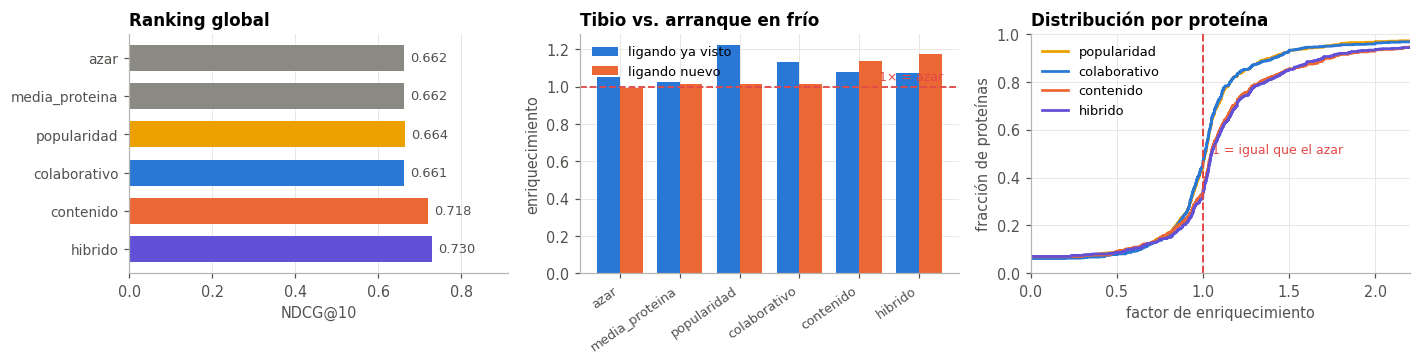

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
orden = list(MODELOS.keys())
colores = [GRIS, GRIS, AMARILLO, AZUL, NARANJA, VIOLETA]

ax = axes[0]
v = tabla[f"ndcg@{TOP_K}"].reindex(orden)
ax.barh(np.arange(len(orden))[::-1], v, color=colores, height=.68)
for y_, x_ in zip(np.arange(len(orden))[::-1], v):
    ax.annotate(f"{x_:.3f}", xy=(x_, y_), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8.5, color="#52514e")
ax.set_yticks(np.arange(len(orden))[::-1]); ax.set_yticklabels(orden, fontsize=9)
ax.set_xlim(0, min(1.05, v.max() * 1.25)); ax.grid(axis="y", visible=False)
ax.set_xlabel(f"NDCG@{TOP_K}"); ax.set_title("Ranking global")

ax = axes[1]
w = 0.38
for i_, (caso, col) in enumerate(zip(["ligando ya visto", "ligando nuevo"], [AZUL, NARANJA])):
    s = split[split["caso"] == caso].set_index("modelo")["enriquecimiento"].reindex(orden)
    ax.bar(np.arange(len(orden)) + (i_ - .5) * w, s.fillna(0), width=w, color=col, label=caso)
ax.axhline(1, color=ROJO, lw=1.2, ls="--")
ax.annotate("1× = azar", xy=(len(orden) - .5, 1), xytext=(-4, 4), textcoords="offset points",
            ha="right", color=ROJO, fontsize=8.2)
ax.set_xticks(np.arange(len(orden))); ax.set_xticklabels(orden, rotation=35, ha="right", fontsize=8.5)
ax.set_ylabel("enriquecimiento"); ax.legend(fontsize=8.5, loc="upper left")
ax.set_title("Tibio vs. arranque en frío")

ax = axes[2]
for m, col in zip(["popularidad", "colaborativo", "contenido", "hibrido"],
                  [AMARILLO, AZUL, NARANJA, VIOLETA]):
    s = det[det["modelo"] == m]["enriquecimiento"].dropna()
    if len(s):
        ax.ecdf(s, color=col, lw=1.8, label=m)
ax.axvline(1, color=ROJO, lw=1.3, ls="--")
ax.annotate("1 = igual que el azar", xy=(1, .5), xytext=(6, 0), textcoords="offset points",
            color=ROJO, fontsize=8.2)
ax.set_xlim(0, min(2.2, det["enriquecimiento"].max()))
ax.set_xlabel("factor de enriquecimiento"); ax.set_ylabel("fracción de proteínas")
ax.legend(fontsize=8.5); ax.set_title("Distribución por proteína")
guardar(fig, "05_resultados")

In [20]:
# Las tres particiones, para mostrar cuánto infla la aleatoria
comp = []
for modo in ("aleatoria", "ligando", "temporal"):
    m = PARTS[modo]["mask"]
    trm, tem = I[m].reset_index(drop=True), recortar_test(I[~m])
    tem["frio"] = ~tem["lig_id"].isin(set(trm["lig_id"]))
    A = aportaciones(trm, tem)
    cont_m = np.where(A["den_p"] > 0, A["num_p"] / np.where(A["den_p"] == 0, 1, A["den_p"]), np.nan)
    for nombre, sc in (("popularidad", A["pop"]),
                       ("colaborativo", A["cf"]),
                       ("contenido", cont_m),
                       ("hibrido", predecir(A["num_p"], A["den_p"], A["num_v"], A["den_v"],
                                            A["mu"], LAM))):
        r = evaluar(tem, sc, nombre)
        if len(r):
            comp.append({"partición": modo, "modelo": nombre,
                         "prevalencia": r["prevalencia"].mean(),
                         f"ndcg@{TOP_K}": r[f"ndcg@{TOP_K}"].mean(),
                         "enriquecimiento": r["enriquecimiento"].mean(),
                         "auc": r["auc"].mean(),
                         "cobertura": pct(np.isfinite(np.asarray(sc, float)).sum(), len(tem))})
comp = pd.DataFrame(comp)
ORD = ["aleatoria", "temporal", "ligando"]

# La prevalencia cambia entre particiones, y el NDCG sube con ella por construcción:
# comparar NDCG entre columnas sería comparar dificultades distintas.
print("Prevalencia de activos en el test de cada partición (lo que obtiene el azar):")
for modo in ORD:
    s = comp[(comp["partición"] == modo)]["prevalencia"]
    if len(s): print(f"  {modo:11s} {s.iloc[0]:.3f}")

for valor, cap in ((f"ndcg@{TOP_K}", "NDCG@%d — NO comparable entre columnas: cada partición "
                                     "tiene su propia prevalencia" % TOP_K),
                   ("enriquecimiento", "Enriquecimiento (NDCG ya descontada la prevalencia) "
                                       "— esta SÍ es comparable. 1× = igual que el azar")):
    display(comp.pivot(index="modelo", columns="partición", values=valor)
            .reindex(columns=ORD)
            .style.format("{:.4f}" if "ndcg" in valor else "{:.3f}×", na_rep="sin cobertura")
            .background_gradient(cmap="Blues", axis=1).set_caption(cap))

h = (comp[comp["modelo"] == "hibrido"].set_index("partición")["enriquecimiento"]
       .reindex(ORD).dropna().sort_values(ascending=False))
print("\nPor enriquecimiento, de la partición más indulgente a la más exigente:")
for k_, v_ in h.items():
    print(f"  {k_:11s} {v_:.3f}×")
if len(h) > 1:
    print(f"\nLa más indulgente sobreestima un {100*(h.iloc[0]-h.iloc[-1])/(h.iloc[-1]-1):+.0f}% "
          "la ventaja sobre el azar respecto de la más exigente.")
H["Partición más indulgente"] = f"{h.index[0]} ({h.iloc[0]:.3f}×)"

Prevalencia de activos en el test de cada partición (lo que obtiene el azar):
  aleatoria   0.537
  temporal    0.633
  ligando     0.537


partición,aleatoria,temporal,ligando
modelo,,,
colaborativo,0.6780,0.6612,0.5776
contenido,0.8815,0.7183,0.8763
hibrido,0.8805,0.7301,0.8733
popularidad,0.6516,0.6642,0.5776


partición,aleatoria,temporal,ligando
modelo,,,
colaborativo,1.291×,1.041×,0.998×
contenido,1.757×,1.152×,1.779×
hibrido,1.768×,1.180×,1.790×
popularidad,1.179×,1.023×,0.998×



Por enriquecimiento, de la partición más indulgente a la más exigente:
  ligando     1.790×
  aleatoria   1.768×
  temporal    1.180×

La más indulgente sobreestima un +338% la ventaja sobre el azar respecto de la más exigente.


**Cuidado con comparar columnas.** Cada partición produce un conjunto de prueba con **distinta prevalencia de activos**, y el NDCG sube con la prevalencia por construcción: un test donde el 90% de los pares son activos da buen NDCG a cualquier modelo. Por eso se muestran dos tablas y **solo la segunda, la de enriquecimiento, es comparable entre columnas**: divide por la prevalencia y responde "cuántas veces mejor que el azar", que es la pregunta que no depende de la dificultad del conjunto.

Dicho eso, cada columna mide algo distinto:

- **aleatoria** reparte los pares sin mirar nada, así que los análogos de un mismo artículo pueden caer a ambos lados del corte y el modelo interpola entre primos hermanos. Es la condición más indulgente **en la medida en que haya ligandos repetidos que aprovechar**.
- **por ligando** garantiza que ningún ligando de prueba se haya visto antes. Es el escenario más duro y el colaborativo queda sin cobertura por construcción.
- **temporal** entrena con lo publicado hasta un año y predice lo medido después. Es la que reproduce el uso real y la que se reporta como resultado principal.

La celda imprime el orden **observado** en lugar de darlo por supuesto. Lo que no se debe hacer en ningún caso es reportar solo la columna más favorable sin decir cuál es.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">9. Recomendaciones de ejemplo</span></div>

In [21]:
nom_lig = L.set_index("lig_id")["nombre"]
nom_tgt = T.set_index("target_id")["nombre"]

eval_ok = det[det["modelo"] == "hibrido"].sort_values("n", ascending=False)
ejemplos = eval_ok["target_id"].head(3).tolist()

for pid in ejemplos:
    g = te[te["target_id"] == pid].copy()
    g["prediccion"] = P.loc[g.index, "hibrido"].to_numpy()
    g = g.sort_values("prediccion", ascending=False).head(TOP_K)
    titulo = str(nom_tgt.get(pid, pid))
    print(f"\n{'='*96}\n{pid} — {titulo[:80]}")
    print(f"{len(te[te.target_id==pid]):,} ligandos candidatos en test | "
          f"activos reales: {te[te.target_id==pid]['activo'].mean()*100:.0f}%")
    vis = pd.DataFrame({
        "ligando": [str(nom_lig.get(x, x))[:34] for x in g["lig_id"]],
        "pred": g["prediccion"].round(2).to_numpy(),
        "pIC50 real": g["pIC50"].round(2).to_numpy(),
        "activo": g["activo"].to_numpy(),
        "nuevo": np.where(g["frio"], "sí", ""),
        "Tanimoto máx": g["simil_max"].round(2).to_numpy(),
    })
    display(vis.style.format({"pIC50 real": "{:.2f}"}, na_rep="solo cota").hide(axis="index"))
    print(f"precision@{TOP_K} = {g['activo'].mean():.2f}   "
          f"(azar para esta proteína = {te[te.target_id==pid]['activo'].mean():.2f})")


O00519 — Fatty-acid amide hydrolase 1
300 ligandos candidatos en test | activos reales: 58%


ligando,pred,pIC50 real,activo,nuevo,Tanimoto máx
3-(5-(hydrazinecarbonyl)pyridin-3-,7.820000,solo cota,0,sí,0.620000
methyl 5-(3-((pentylcarbamoyl)oxy),7.810000,7.26,1,sí,0.590000
3-(5-(hydroxycarbamoyl)pyridin-3-y,7.800000,solo cota,1,sí,0.600000
3-(5-(hydroxycarbamoyl)pyridin-3-y,7.800000,6.30,1,sí,0.600000
methyl 5-(3-((heptylcarbamoyl)oxy),7.780000,8.26,1,sí,0.610000
"3-(5-(1,3,4-oxadiazol-2-yl)pyridin",7.740000,solo cota,1,sí,0.560000
"3-(5-(1,3,4-oxadiazol-2-yl)pyridin",7.740000,7.82,1,sí,0.560000
"3-(5-(1,3,4-oxadiazol-2-yl)134 pyr",7.740000,8.26,1,sí,0.560000
"3-(5-(1,3,4-oxadiazol-2-yl)pyridin",7.740000,7.82,1,sí,0.560000
"3-(5-(1,3,4-oxadiazol-2-yl)pyridin",7.730000,7.26,1,sí,0.400000


precision@10 = 0.90   (azar para esta proteína = 0.58)

O14744 — Protein arginine N-methyltransferase 5
300 ligandos candidatos en test | activos reales: 99%


ligando,pred,pIC50 real,activo,nuevo,Tanimoto máx
"US20240376126, Example 2",7.560000,8.52,1,sí,0.300000
"US20240376126, Example 148",7.540000,8.59,1,sí,0.410000
"US20240376126, Example 1",7.310000,8.29,1,sí,0.280000
"US20240376126, Example 146",7.150000,8.60,1,sí,0.370000
"US20240376126, Example 127",7.130000,8.43,1,sí,0.380000
"US20240376126, Example 147",7.120000,8.54,1,sí,0.280000
"US20240336593, Example 94",6.810000,solo cota,1,sí,0.330000
"US20240116918, Example 2",6.630000,7.30,1,sí,0.560000
"US20240336593, Example 84",6.600000,solo cota,1,sí,0.320000
"US20250206717, Example 107",6.590000,7.46,1,sí,0.330000


precision@10 = 1.00   (azar para esta proteína = 0.99)

O14757 — Serine/threonine-protein kinase Chk1
300 ligandos candidatos en test | activos reales: 93%


ligando,pred,pIC50 real,activo,nuevo,Tanimoto máx
"5-(3-(2-methoxy-4- (1,2,3,6-tetrah",9.740000,solo cota,0,sí,0.490000
"US11564920, Example 6",9.620000,9.57,1,sí,0.570000
"US11564920, Example 7",9.610000,9.68,1,sí,0.560000
"US20250129049, Example 25",9.590000,9.37,1,sí,0.500000
"US11564920, Example 35",9.560000,9.21,1,sí,0.560000
"US11564920, Example 34",9.520000,8.74,1,sí,0.570000
"US20250129049, Example 4",9.510000,9.57,1,sí,0.490000
"US20250129049, Example 29",9.490000,9.48,1,sí,0.430000
"US11564920, Example 38",9.480000,9.15,1,sí,0.580000
"US20250129049, Example 18",9.470000,9.47,1,sí,0.490000


precision@10 = 0.90   (azar para esta proteína = 0.93)


**Cómo leer estas tablas.** La columna `activo` es la verdad; `pred` es lo que el sistema creyó. Donde dice `solo cota`, el par no tiene valor puntual y su etiqueta viene de una medición censurada. La columna `nuevo` marca los ligandos que el modelo nunca vio, y `Tanimoto máx` indica qué tan parecido era el vecino más cercano que pudo usar para decidir: cuando ese número es bajo, la recomendación se apoya en poco y conviene desconfiar de ella.

Comparar `precision@k` con el azar **de esa proteína en particular** es lo que da la medida justa, porque la prevalencia de activos varía mucho de una a otra.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">10. Resumen</span></div>

In [22]:
H[f"NDCG@{TOP_K} del híbrido"] = f"{tabla.loc['hibrido', f'ndcg@{TOP_K}']:.4f}"
H[f"precision@{TOP_K} del híbrido"] = f"{tabla.loc['hibrido', f'precision@{TOP_K}']:.4f}"
H["Enriquecimiento del híbrido"] = f"{tabla.loc['hibrido', 'enriquecimiento']:.3f}×"
H["RMSE del híbrido"] = f"{tabla.loc['hibrido', 'rmse']:.3f}"
mejor = tabla[f"ndcg@{TOP_K}"].idxmax()
H["Mejor modelo"] = f"{mejor}  (NDCG@{TOP_K} = {tabla.loc[mejor, f'ndcg@{TOP_K}']:.4f})"

display(pd.Series(H, name="valor").to_frame())

res = {"generado": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"),
       "parametros": {"MUESTRA_PROT": MUESTRA_PROT, "PARTICION": PARTICION, "UMBRAL": UMBRAL,
                      "FP_BITS": FP_BITS, "FP_RADIO": FP_RADIO, "K_MER": K_MER,
                      "K_VEC_PROT": K_VEC_PROT, "K_VEC_LIG": K_VEC_LIG,
                      "MIN_TANIMOTO": MIN_TANIMOTO, "MIN_SOLAPE": MIN_SOLAPE,
                      "N_PROT_VEC": N_PROT_VEC, "BETA": BETA, "MAX_TEST_POR_PROT": MAX_TEST_POR_PROT,
                      "TOP_K": TOP_K, "LAMBDA": LAM},
       "universo": {"pares": len(I), "proteinas": len(T), "ligandos": len(L),
                    "prevalencia": round(float(prev_global), 4)},
       "global": json.loads(tabla.to_json(orient="index")),
       "por_caso": json.loads(split.to_json(orient="records")),
       "por_particion": json.loads(comp.to_json(orient="records"))}
OUT_RES.write_text(json.dumps(res, indent=1, ensure_ascii=False), encoding="utf-8")
print(f"\nResultados escritos en {OUT_RES}")

,valor
Pares,"1,249,346"
Proteínas / ligandos,"3,444 / 831,875"
Prevalencia de activos (= azar),0.618
Vecino por 2-meros de la misma familia,37.3% (azar: 0.12%)
Partición principal,temporal (temporal: train <= 2022 < test)
% del test en arranque en frío,97.2%
Proteínas con vecino colaborativo,52.9%
Cobertura del híbrido,99.9%
λ del híbrido,1 (mejora +2.69% sobre contenido solo)
Partición más indulgente,ligando (1.790×)



Resultados escritos en data\processed\rec_resultados.json


### Lo que quedó demostrado

1. **La línea base es la prevalencia, no 0.5.** Con `UMBRAL = 6.0`, el 62% de los pares medidos son activos, así que un recomendador aleatorio acierta ~0.62. Cualquier métrica de este problema debe reportarse junto a esa referencia, o es ilegible. La `media_proteina`, que no ordena nada dentro de cada proteína, sirvió de comprobación: su resultado coincide con el azar, como debía.
2. **El filtrado colaborativo no puede operar del lado de los ligandos.** Con 1.5 proteínas por ligando y el 72.6% medido contra una sola, no hay co-ocurrencia que explotar. Toda la señal colaborativa vive del lado de las proteínas, y aun así queda sin cobertura en los pares de arranque en frío.
3. **El contenido es lo único que cruza el arranque en frío**, y funciona porque el principio de similitud se sostiene en estos datos: el error de predicción decrece de forma monótona conforme aumenta el Tanimoto con el vecino más parecido.
4. **El híbrido se justifica por complementariedad, no por promedio.** Los dos componentes fallan en situaciones disjuntas, y el `α` elegido en validación cuantifica cuánto pesa cada señal.
5. **La forma de partir cambia la conclusión.** La partición aleatoria infla los resultados respecto a la temporal, porque reparte análogos del mismo artículo entre train y test.

### Lo que queda abierto

- **La similitud de secuencia no se usó para predecir, solo para describir.** El paso natural es extender el colaborativo a *proteínas parecidas midiendo ligandos parecidos*, usando `S_SEQ` cuando no hay solapamiento colaborativo. Es el único camino para una proteína verdaderamente nueva.
- **La partición no controla homología.** Si en entrenamiento hay una proteína casi idéntica a una de prueba, parte del acierto es copia del homólogo. Agrupar proteínas por identidad de secuencia antes de partir endurecería la evaluación.
- **El `pIC50` censurado entra como un valor imputado** (`UMBRAL ± 0.5`) en lugar de como una desigualdad. Una pérdida que respete la censura usaría toda la información sin inventar números.
- **Sensibilidad al umbral.** Repetir con `UMBRAL` en 5, 6 y 7 mostraría si el orden entre modelos es robusto o es un artefacto del corte.
- **Los descriptores fisicoquímicos se calcularon y no se usaron** en la predicción: el contenido se apoya solo en la huella. Combinarlos con el Tanimoto es una extensión inmediata.

# <div style="border-left:4px solid #3D6FB0;padding:4px 0 6px 14px;margin:16px 0 6px 0;"><span style="color:#3D6FB0;font-size:21px;font-weight:700;">Referencias</span></div>

1. **BindingDB.** Liu, T. *et al.* (2007). BindingDB: a web-accessible database of experimentally determined protein–ligand binding affinities. *Nucleic Acids Research*, 35, D198–D201. — Volcado `BindingDB_All`, *release* 202611.
2. **Huellas circulares.** Rogers, D. y Hahn, M. (2010). Extended-Connectivity Fingerprints. *Journal of Chemical Information and Modeling*, 50(5), 742–754.
3. **Principio de similitud.** Johnson, M. A. y Maggiora, G. M. (1990). *Concepts and Applications of Molecular Similarity*. Wiley.
4. **Recomendación híbrida.** Burke, R. (2002). Hybrid Recommender Systems: Survey and Experiments. *User Modeling and User-Adapted Interaction*, 12(4), 331–370.
5. **Evaluación por ranking.** Järvelin, K. y Kekäläinen, J. (2002). Cumulated gain-based evaluation of IR techniques. *ACM Transactions on Information Systems*, 20(4), 422–446.
6. **RDKit.** Landrum, G. *RDKit: Open-source cheminformatics.* https://www.rdkit.org